In [2]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:
# Run in a Colab cell
!pip install -q "transformers>=4.33.2" datasets evaluate jiwer accelerate sentencepiece\
                   pillow matplotlib scikit-learn


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 76.6 MB/s eta 0:00:00


In [4]:
# Paths - update if needed
train_img_dir = "/content/drive/MyDrive/prepared_dataset/train/labels"   # contains .jpg
train_label_dir = "/content/drive/MyDrive/prepared_dataset/train/labels" # contains .json (same folder in your case)
test_img_dir  = "/content/drive/MyDrive/prepared_dataset/test/labels"
test_label_dir = "/content/drive/MyDrive/prepared_dataset/test/labels"

# Where to save models / prepared data
OUT_ROOT = "/content/drive/MyDrive/DL Dataset/model_comparisons"
import os
os.makedirs(OUT_ROOT, exist_ok=True)


In [5]:
import os, json
from tqdm import tqdm

def load_dataset_recursive(img_dir, label_dir):
    dataset = []
    for root, _, files in os.walk(label_dir):
        for file in files:
            if file.lower().endswith(".json"):
                json_path = os.path.join(root, file)
                with open(json_path, "r", encoding="utf-8") as f:
                    annotations = json.load(f)
                # Combine annotation texts into one string (preserve spaces)
                text = " ".join([ann.get("text","") for ann in annotations]).strip()
                img_name = file.replace(".json", ".jpg")
                img_path = None
                # search recursively for the image
                for r, _, fs in os.walk(img_dir):
                    if img_name in fs:
                        img_path = os.path.join(r, img_name)
                        break
                if img_path and text:
                    dataset.append({"image_path": img_path, "text": text})
    return dataset

train_data = load_dataset_recursive(train_img_dir, train_label_dir)
test_data  = load_dataset_recursive(test_img_dir, test_label_dir)

print("Train samples:", len(train_data))
print("Test samples :", len(test_data))
print("Example:", train_data[0])


Train samples: 515
Test samples : 172
Example: {'image_path': '/content/drive/MyDrive/prepared_dataset/train/labels/eng_EU_253.jpg', 'text': 'These Bliss Ballons help carry away your worries. Write them down then imagine them floating away...'}


In [6]:
from datasets import Dataset
ds_train = Dataset.from_list(train_data)
ds_test  = Dataset.from_list(test_data)

# quick shuffling and small validation split (optional)
ds_train = ds_train.shuffle(seed=42)
ds_train = ds_train.train_test_split(test_size=0.1, seed=42)
# ds_train["train"], ds_train["test"] are created - to keep naming: use train_split/test_split
train_split = ds_train["train"]
val_split   = ds_train["test"]
test_split  = ds_test  # keep full test


In [7]:
import torch
from transformers import TrOCRProcessor, VisionEncoderDecoderModel, Seq2SeqTrainer, Seq2SeqTrainingArguments

# --- Model & Processor ---
model_name = "microsoft/trocr-base-handwritten"
processor_trocr = TrOCRProcessor.from_pretrained(model_name)
model_trocr = VisionEncoderDecoderModel.from_pretrained(model_name)

device = "cuda" if torch.cuda.is_available() else "cpu"
model_trocr.to(device)


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/224 [00:00<?, ?B/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

... (2 outputs left out)

model.safetensors:   0%|          | 0.00/1.33G [00:00<?, ?B/s]

Some weights of VisionEncoderDecoderModel were not initialized from the model checkpoint at microsoft/trocr-base-handwritten and are newly initialized: ['encoder.pooler.dense.bias', 'encoder.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


generation_config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

VisionEncoderDecoderModel(
  (encoder): ViTModel(
    (embeddings): ViTEmbeddings(
      (patch_embeddings): ViTPatchEmbeddings(
        (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (encoder): ViTEncoder(
      (layer): ModuleList(
        (0-11): 12 x ViTLayer(
          (attention): ViTAttention(
            (attention): ViTSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=False)
              (key): Linear(in_features=768, out_features=768, bias=False)
              (value): Linear(in_features=768, out_features=768, bias=False)
            )
            (output): ViTSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
          )
          (intermediate): ViTIntermediate(
            (dense): Linear(in_features=768, out_features=3072, bias=True)
            (i

In [8]:
from PIL import Image

def preprocess(batch):
    images = [Image.open(p).convert("RGB") for p in batch["image_path"]]

    # Convert images to pixel_values tensors
    pixel_values = processor_trocr(images, return_tensors="pt").pixel_values

    # Convert labels to token IDs
    labels = processor_trocr.tokenizer(batch["text"], padding="max_length", truncation=True, max_length=128).input_ids

    return {"pixel_values": list(pixel_values), "labels": labels}  # keep pixel_values as list for collator


In [9]:
from torch.nn.utils.rnn import pad_sequence
import torch

def collate_fn_trOCR(batch):
    # Stack pixel_values (convert each list to tensor first)
    pixel_values = torch.stack([torch.tensor(b["pixel_values"]) for b in batch])

    # Convert labels to tensors and pad
    labels = [torch.tensor(b["labels"]) for b in batch]
    labels = pad_sequence(labels, batch_first=True, padding_value=processor_trocr.tokenizer.pad_token_id)

    return {
        "pixel_values": pixel_values,
        "labels": labels
    }


In [10]:
from transformers import TrOCRProcessor, VisionEncoderDecoderModel

# Load model and processor
processor_trocr = TrOCRProcessor.from_pretrained("microsoft/trocr-base-handwritten")
model_trocr = VisionEncoderDecoderModel.from_pretrained("microsoft/trocr-base-handwritten")

# Make sure decoder_start_token_id is set
if model_trocr.config.decoder_start_token_id is None:
    model_trocr.config.decoder_start_token_id = processor_trocr.tokenizer.cls_token_id
    model_trocr.config.pad_token_id = processor_trocr.tokenizer.pad_token_id
    model_trocr.config.eos_token_id = processor_trocr.tokenizer.sep_token_id


Some weights of VisionEncoderDecoderModel were not initialized from the model checkpoint at microsoft/trocr-base-handwritten and are newly initialized: ['encoder.pooler.dense.bias', 'encoder.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [11]:
train_proc = train_split.map(preprocess, batched=True, batch_size=2)
val_proc   = val_split.map(preprocess, batched=True, batch_size=2)
test_proc  = test_split.map(preprocess, batched=True, batch_size=2)


Map:   0%|          | 0/463 [00:00<?, ? examples/s]

Map:   0%|          | 0/52 [00:00<?, ? examples/s]

Map:   0%|          | 0/172 [00:00<?, ? examples/s]

In [12]:
from transformers import Seq2SeqTrainer, Seq2SeqTrainingArguments

training_args = Seq2SeqTrainingArguments(
    output_dir="./trocr_output",
    report_to="none",       # disable all logging integrations
    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    predict_with_generate=True,
    save_strategy="steps",
    logging_steps=50,
    save_steps=200,
    eval_steps=100,
    num_train_epochs=5,
    learning_rate=5e-5,
    save_total_limit=2,
    fp16=True,
    remove_unused_columns=False
)

trainer_trocr = Seq2SeqTrainer(
    model=model_trocr,
    args=training_args,
    train_dataset=train_proc,
    eval_dataset=val_proc,
    tokenizer=processor_trocr,
    data_collator=collate_fn_trOCR
)



/tmp/ipython-input-862526845.py:20: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Seq2SeqTrainer.__init__`. Use `processing_class` instead.
  trainer_trocr = Seq2SeqTrainer(


In [13]:
import os
os.environ["WANDB_MODE"] = "disabled"
os.environ["WANDB_DISABLED"] = "true"


In [14]:
# --- Train ---
trainer_trocr.train()

# --- Save model and processor ---
model_trocr.save_pretrained("./trocr_final")
processor_trocr.save_pretrained("./trocr_final")

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': 0}.
`loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Step,Training Loss
50,6.249500
100,4.840100
150,4.844100
200,4.728300
250,4.620700
300,4.389100
350,4.108000
400,4.544500
450,4.006000
500,4.137500


[]

In [16]:
# Evaluate model performance on validation set
results = trainer_trocr.evaluate()

print("📊 Evaluation Metrics:")
for k, v in results.items():
    print(f"{k}: {v:.4f}")


📊 Evaluation Metrics:
eval_loss: 4.3544
eval_runtime: 16.8969
eval_samples_per_second: 3.0770
eval_steps_per_second: 1.5390
epoch: 5.0000


In [19]:
import evaluate
import numpy as np

# Load accuracy metric using the new library
metric = evaluate.load("accuracy")

def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    predictions = np.argmax(predictions, axis=-1)

    # Replace -100 (ignored tokens) with pad token for decoding
    labels = np.where(labels != -100, labels, processor_trocr.tokenizer.pad_token_id)

    # Decode
    decoded_preds = processor_trocr.batch_decode(predictions, skip_special_tokens=True)
    decoded_labels = processor_trocr.batch_decode(labels, skip_special_tokens=True)

    # Compute character-level accuracy
    acc = np.mean([p == l for p, l in zip(decoded_preds, decoded_labels)])
    return {"char_accuracy": acc}


In [20]:
wer_metric = evaluate.load("wer")
cer_metric = evaluate.load("cer")

def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    predictions = np.argmax(predictions, axis=-1)
    labels = np.where(labels != -100, labels, processor_trocr.tokenizer.pad_token_id)

    decoded_preds = processor_trocr.batch_decode(predictions, skip_special_tokens=True)
    decoded_labels = processor_trocr.batch_decode(labels, skip_special_tokens=True)

    wer = wer_metric.compute(predictions=decoded_preds, references=decoded_labels)
    cer = cer_metric.compute(predictions=decoded_preds, references=decoded_labels)
    return {"WER": wer, "CER": cer}


In [21]:
trainer_trocr.compute_metrics = compute_metrics

results = trainer_trocr.evaluate()
print("📊 Evaluation Results:", results)


📊 Evaluation Results: {'eval_loss': 4.388705253601074, 'eval_WER': 0.9974582425562818, 'eval_CER': 0.997004038035691, 'eval_runtime': 32.6717, 'eval_samples_per_second': 1.592, 'eval_steps_per_second': 0.796, 'epoch': 5.0}


In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import torch

def visualize_prediction(example):
    # Load image
    image = Image.open(example["image_path"]).convert("RGB")

    # If 'labels' exists, decode it
    label_text = ""
    if "labels" in example:
        label_text = processor_trocr.tokenizer.decode(example["labels"], skip_special_tokens=True)

    # Generate prediction
    pixel_values = processor_trocr(image, return_tensors="pt").pixel_values.to(model_trocr.device)
    generated_ids = model_trocr.generate(pixel_values)
    pred_text = processor_trocr.batch_decode(generated_ids, skip_special_tokens=True)[0]

    # Plot results
    plt.figure(figsize=(6,6))
    plt.imshow(image)
    plt.axis("off")
    title = f"🔍 Pred: {pred_text}"
    if label_text:
        title += f"\n✅ True: {label_text}"
    plt.title(title, fontsize=10)
    plt.show()

# Use the preprocessed dataset for visualization
for i in range(3):
    visualize_prediction(test_proc[i])


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128201 (\N{CHART WITH DOWNWARDS TREND}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


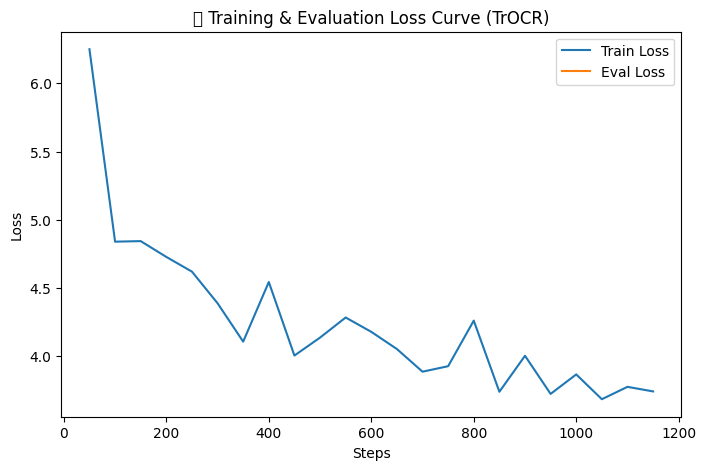

In [26]:
import pandas as pd
import matplotlib.pyplot as plt

logs = pd.DataFrame(trainer_trocr.state.log_history)
loss_df = logs[["step", "loss", "eval_loss"]].dropna(subset=["loss"])

plt.figure(figsize=(8,5))
plt.plot(loss_df["step"], loss_df["loss"], label="Train Loss")
if "eval_loss" in loss_df.columns:
    plt.plot(loss_df["step"], loss_df["eval_loss"], label="Eval Loss")
plt.xlabel("Steps")
plt.ylabel("Loss")
plt.title("📉 Training & Evaluation Loss Curve (TrOCR)")
plt.legend()
plt.show()


In [27]:
# Save trained TrOCR model and processor
save_path = "./trocr_final"

model_trocr.save_pretrained(save_path)
processor_trocr.save_pretrained(save_path)

print(f"✅ Model and processor saved to: {save_path}")


✅ Model and processor saved to: ./trocr_final


In [28]:
from google.colab import files
!zip -r trocr_final.zip ./trocr_final
files.download("trocr_final.zip")


  adding: trocr_final/ (stored 0%)
  adding: trocr_final/tokenizer_config.json (deflated 75%)
  adding: trocr_final/vocab.json (deflated 59%)
  adding: trocr_final/generation_config.json (deflated 32%)
  adding: trocr_final/special_tokens_map.json (deflated 85%)
  adding: trocr_final/tokenizer.json (deflated 82%)
  adding: trocr_final/config.json (deflated 63%)
  adding: trocr_final/merges.txt (deflated 53%)
  adding: trocr_final/model.safetensors (deflated 7%)
  adding: trocr_final/preprocessor_config.json (deflated 48%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>